# Токенизация и нормализация текста

## Токенизация

In [10]:
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize

In [20]:
text = """
Илья Сегалович родился в семье советского геофизика В.И.Сегаловича. Детство провёл в
Казахстане. В Республиканской физико-математической школе познакомился с будущим сооснователем
«Яндекса» Аркадием Воложем. В 1981 году поступил в Московский геологоразведочный институт
им.Орджоникидзе.

С самого основания «Яндекса» и до своей смерти Илья Сегалович занимал позицию директора по
технологиям, был ключевым архитектором поисковых технологий и инициатором многих продуктов
компании, например, Яндекс.Директа, голосового помощника «Алиса» и беспилотного автомобиля.
"""

Токен - минимальная единица анализа текста. Гранулярность зависит от задачи.

**Зачем?**

**Где применяется?**

sent_tokenize
Модель учитывает не только точки, но и заглавные буквы, сокращения, числа.

In [17]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [21]:
sentences = sent_tokenize(text)

In [22]:
print(sentences)

['\nИлья Сегалович родился в семье советского геофизика В.И.Сегаловича.', 'Детство провёл в\nКазахстане.', 'В Республиканской физико-математической школе познакомился с будущим сооснователем\n«Яндекса» Аркадием Воложем.', 'В 1981 году поступил в Московский геологоразведочный институт\nим.Орджоникидзе.', 'С самого основания «Яндекса» и до своей смерти Илья Сегалович занимал позицию директора по\nтехнологиям, был ключевым архитектором поисковых технологий и инициатором многих продуктов\nкомпании, например, Яндекс.Директа, голосового помощника «Алиса» и беспилотного автомобиля.']


word_tokenize
TreebankWordTokenizer — токенизатор на правилах, обученный на Penn Treebank. Он отделяет пунктуацию, но сохраняет некоторые составные единицы.

In [23]:
text = "I can't COME NOW."

In [24]:
print(word_tokenize(text))

['I', 'ca', "n't", 'COME', 'NOW', '.']


can't

## Регулярные выражения для очистки текста

regex - паттерны в строках. Поиск и замена текста. Regex -  формальный язык описания паттернов в строках. В NLP это основной инструмент удаления шума - легко, в несколько строк

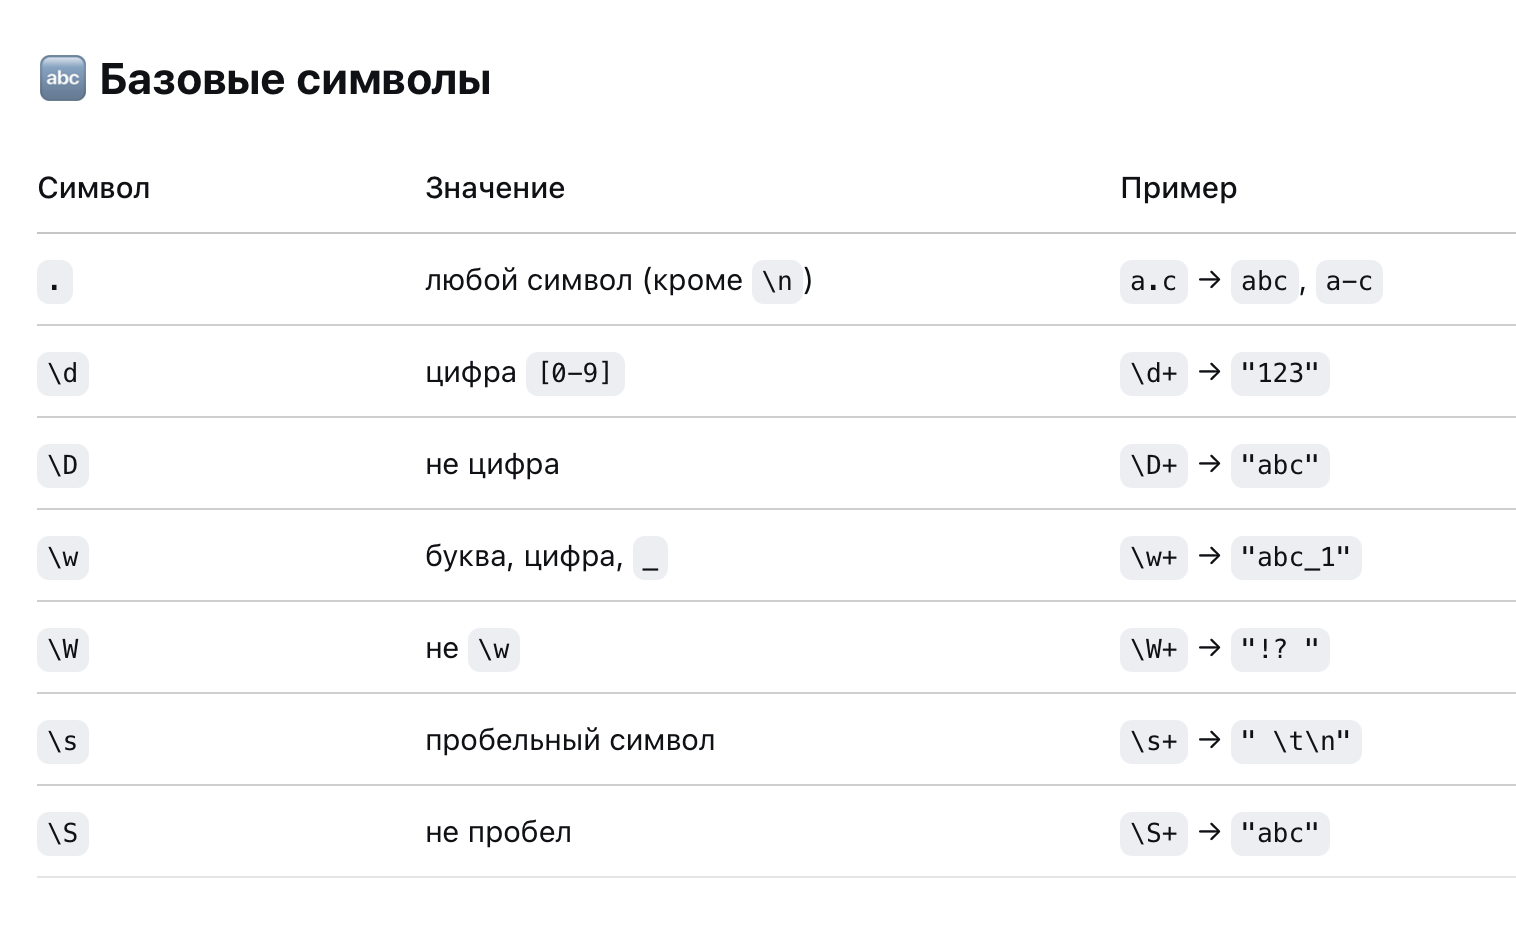

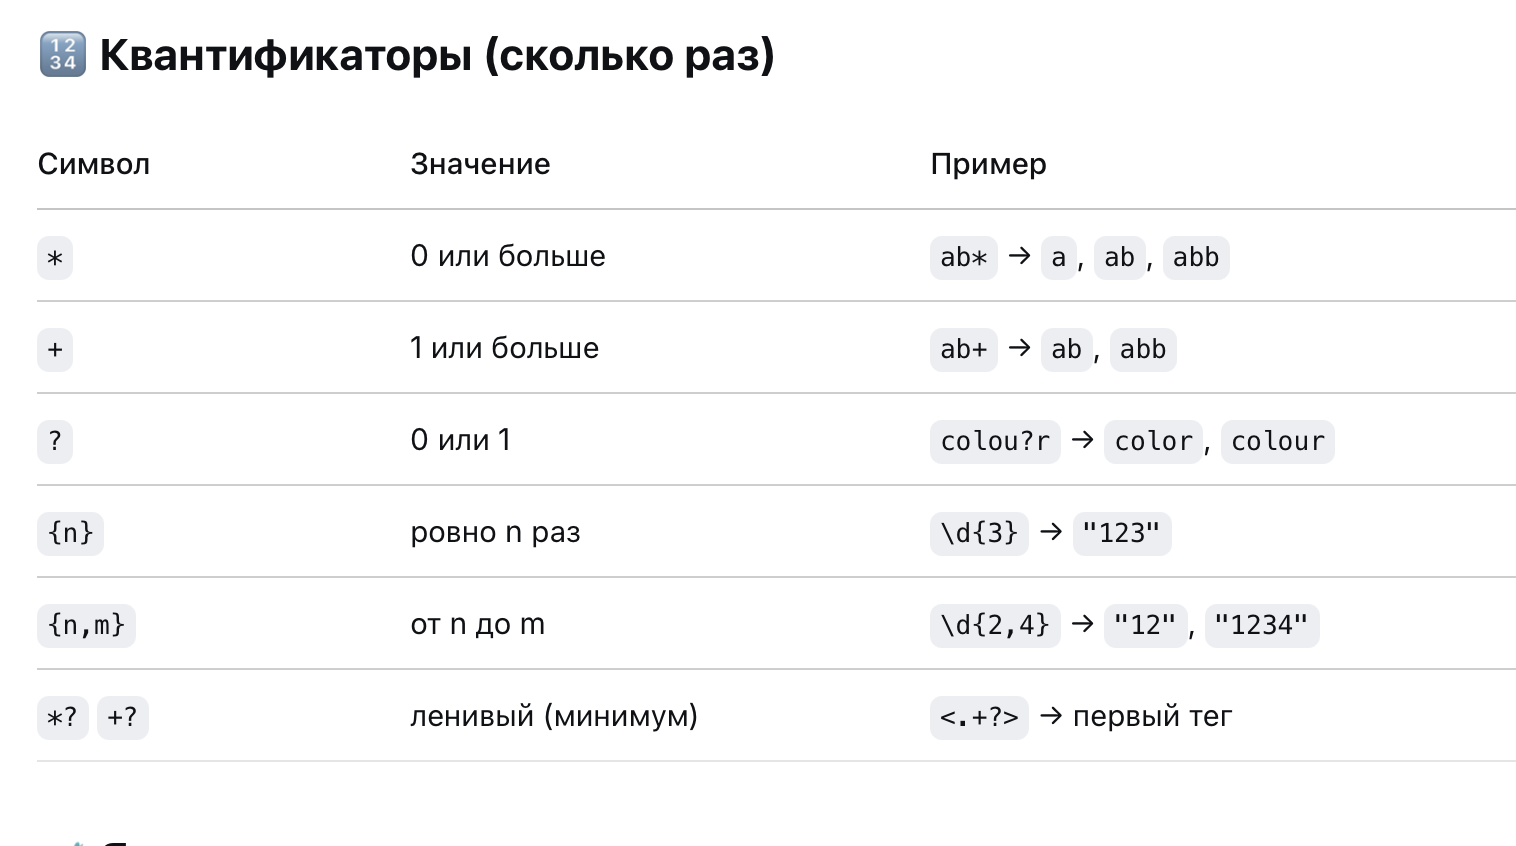

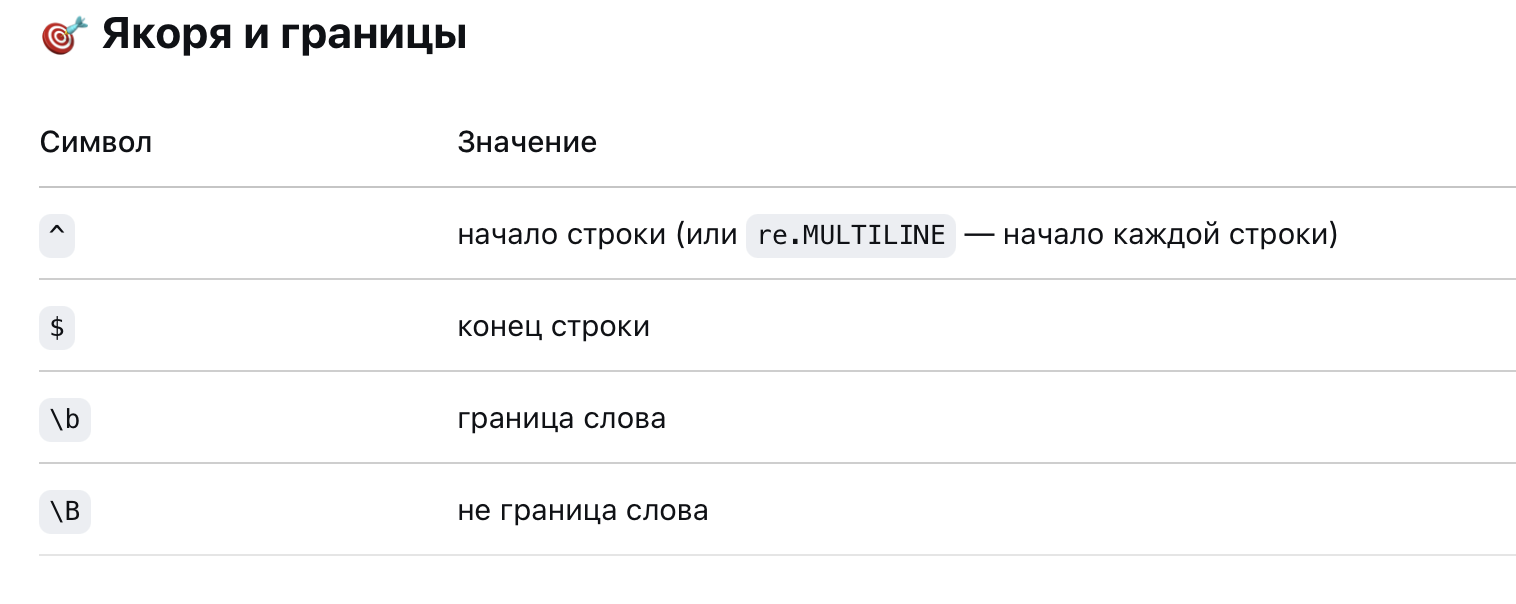

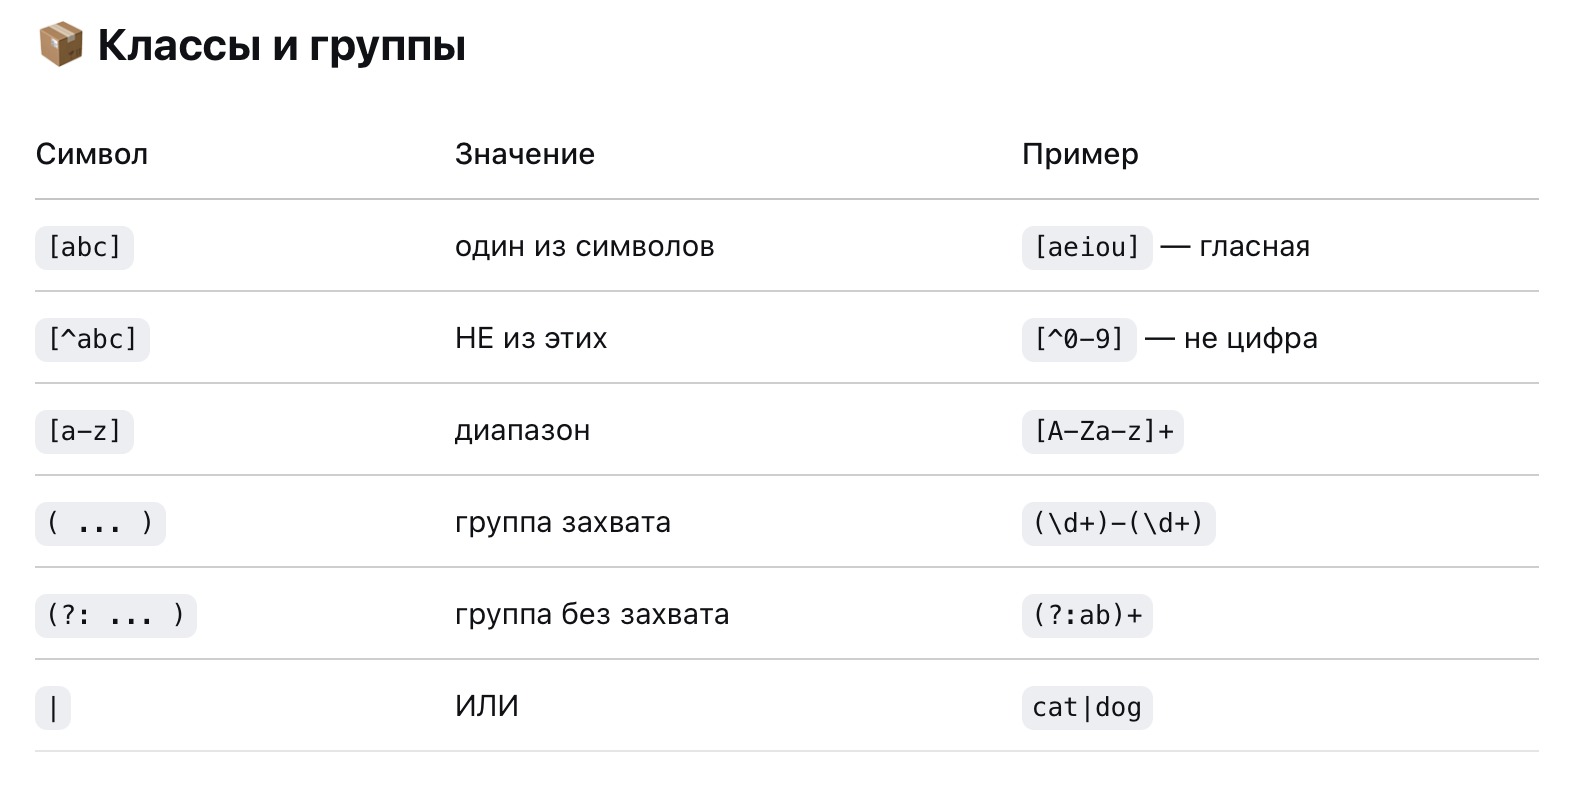

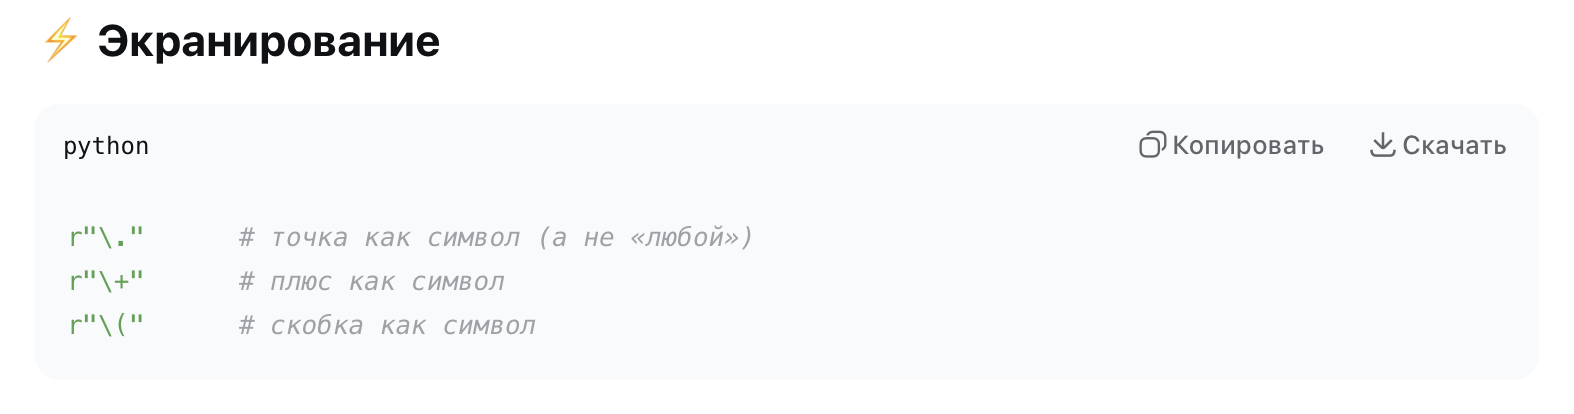

In [25]:
import re

Найти первое совпадение

In [26]:
re.search(r"\d+", "abc 123")

<re.Match object; span=(4, 7), match='123'>

Заменить

In [27]:
re.sub(r"\d+", "#", "a1 b22")

'a# b#'

Часто regex используются для поиска паттернов email, номера телефона и т д
E-mail (упрощённо)
r"[\w.+-]+@[\w-]+\.[\w.-]+"

URL
r"https?://[^\s]+"

Телефон (RU)
r"\+7\s?\(?\d{3}\)?\s?\d{3}-?\d{2}-?\d{2}"

Дата YYYY-MM-DD
r"\d{4}-\d{2}-\d{2}"

Конвейер очистки текста с помощью регулярных выражений

In [29]:
def clean_text(text: str) -> str:
    text = text.lower()                                      # 1. нижний регистр
    text = re.sub(r'\[.*?\]', '', text)                      # 2. скобки (метаданные)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)        # 3. URL
    text = re.sub(r'<.*?>', '', text)                        # 4. HTML-теги
    text = re.sub(r'@\w+', '', text)                         # 5. упоминания
    text = re.sub(r'#\w+', '', text)                         # 6. хэштеги
    text = re.sub(r'[^\w\s]', '', text)                      # 7. пунктуация и спецсимволы
    text = re.sub(r'\s+', ' ', text).strip()                 # 8. пробелы
    return text

In [30]:
text = "Check https://example.com!!! It's <b>great</b> 😍 #nlp"

In [31]:
print(clean_text(text))

check its great


## Стоп-слова, регистр, исправление и замена слов

Стоп-слова - высокочастотные слова, не несущие самостоятельной семантической нагрузки для большинства задач (и, в, на, the, is, at). Их удаление уменьшает шум и размерность (векторизация).

In [32]:
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [33]:
stop_words = set(stopwords.words('english'))

In [34]:
tokens = word_tokenize("This is a sample sentence, showing off stop word filtration.")

In [35]:
filtered = [w for w in tokens if w.lower() not in stop_words and w.isalnum()]

In [36]:
print(filtered)

['sample', 'sentence', 'showing', 'stop', 'word', 'filtration']


Удаление стоп-слов не всегда полезно, например, в машинном переводе

**Приведение к нижнему регистру**

In [37]:
tokens = word_tokenize("This is a SAMPLE text.")
lower_tokens = [w.lower() for w in tokens]

Уничтожает различие между именами собственными и нарицательными

**Исправление орфографических ошибок**

Опечатки создают фантомные токены и снижают точность модели

In [58]:
!pip install pyspellchecker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 16.5 MB/s  0:00:00


In [59]:
from spellchecker import SpellChecker

spell = SpellChecker()
words = ['something', 'is', 'hapenning', 'here']
misspelled = spell.unknown(words)
print(misspelled)  # {'hapenning'}

for word in misspelled:
    print(word, '->', spell.correction(word))

{'hapenning'}
hapenning -> happening


Исправление по наиболее вероятному варианту в частотном словаре и расстоянию редактирования (Левенштейн)

\D(i,j)=min
\begin{cases}
D(i-1,j)+1, & \text{удаление},\\
D(i,j-1)+1, & \text{вставка},\\
D(i-1,j-1)+[a_i \ne b_j], & \text{замена или совпадение},
\end{cases}

где
\begin{cases}
0, & a_i=b_j,\\
1, & a_i\ne b_j.
\end{cases}


**НО:** не учитывает контекст

## Стемминг и лемматизация

Свести словоформы к общей базе

## Стемминг

Стемминг — эвристическое «отсечение» аффиксов по правилам, без обращения к словарю и без учёта части речи. Результат (**стем**) не обязан быть реальным словом языка.

PorterStemmer - удаляет суффиксы, для английского

In [39]:
from nltk.stem import PorterStemmer

In [40]:
ps = PorterStemmer()
words = ['running', 'runs', 'runner', 'happiness', 'happily']

In [41]:
print([ps.stem(w) for w in words])

['run', 'run', 'runner', 'happi', 'happili']


Snowball Stemmer - для русского в том числе

In [42]:
from nltk.stem.snowball import SnowballStemmer

In [43]:
ru_stemmer = SnowballStemmer("russian")

In [44]:
print([ru_stemmer.stem(w) for w in ['машины', 'машиной', 'машинам']])

['машин', 'машин', 'машин']


Плюсы стемминга: быстрота. Минусы - семантически неверные одинаковые стемы (university и universe)

## Лемматизация

Лемматизация — приведение словоформы к лемме — канонической словарной форме с учётом морфологии и части речи. Требует словаря (WordNet) или морфологического анализатора.

**Лемма всегда существует в языке**

In [45]:
from nltk.stem import WordNetLemmatizer
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [46]:
wnl = WordNetLemmatizer()

In [47]:
print(wnl.lemmatize('dogs'))      # dog

dog


In [48]:
print(wnl.lemmatize('churches'))  # church

church


In [49]:
print(wnl.lemmatize('aardwolves'))# aardwolf

aardwolf


In [50]:
print(wnl.lemmatize('abaci'))     # abacus

abacus


По умолчанию pos='n' (существительное). Для глаголов и прилагательных нужно явно указывать часть речи:

In [51]:
print(wnl.lemmatize('running', pos='v'))  # run
print(wnl.lemmatize('better', pos='a'))   # good

run
good


Без указания pos лемматизатор может дать неожиданный результат: lemmatize('running') вернёт running (потому что как существительное это слово уже в словарной форме).

**Лемматизация точнее, но медленнее**

## Особенности обработки русского языка

Русский язык морфологически богаче английского: развитая система падежей, склонений, спряжений. Стемминг «в лоб» даёт много ошибок, поэтому для русского предпочтительна лемматизация специализированными инструментами.

Каждый шаг обработки текста - компромисс. Агрессивная очистка и удаление стоп-слов ускоряют модель, но могут выбросить сигнал (информацию). Лемматизация точнее стемминга, но медленнее. RegexpTokenizer даёт контроль, но требует ручной настройки под домен.

Snowball

In [52]:
ru = SnowballStemmer("russian")
words = ['машина', 'машины', 'машине', 'машину', 'машиной']
print([ru.stem(w) for w in words])
# ['машин', 'машин', 'машин', 'машин', 'машин']

['машин', 'машин', 'машин', 'машин', 'машин']


pymorphy2/pymorphy3 - морфологический анализатор на основе OpenCorpora - даёт лемму, часть речи, падеж, число и другие признаки.

In [53]:
!pip install pymorphy3

In [55]:

import pymorphy3  # или pymorphy2

morph = pymorphy3.MorphAnalyzer()

In [56]:
for word in ['машины', 'машиной', 'машинам', 'бежал', 'красивого']:
    p = morph.parse(word)[0]
    print(f"{word:12} -> {p.normal_form:12} | {p.tag.POS}")

машины       -> машина       | NOUN
машиной      -> машина       | NOUN
машинам      -> машина       | NOUN
бежал        -> бежать       | VERB
красивого    -> красивый     | ADJF


spyCY - токенизация, лемматизация, POS-теггинг

In [60]:
!python -m spacy download ru_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 27.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('ru_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [61]:
import spacy

nlp = spacy.load("ru_core_news_sm")

In [62]:
doc = nlp("Машины едут быстро. Красивого заката не было.")

In [63]:
for token in doc:
    print(token.text, "->", token.lemma_, "|", token.pos_)

Машины -> машина | NOUN
едут -> ехать | VERB
быстро -> быстро | ADV
. -> . | PUNCT
Красивого -> красивый | ADJ
заката -> заката | NOUN
не -> не | PART
было -> быть | VERB
. -> . | PUNCT


**Другие инструменты для русского**


Natasha	- быстрая сегментация и NER, лемматизация через словари

PyMystem3	- обёртка над Yandex Mystem, высокая точность, но проприетарная зависимость

DeepPavlov	- нейросетевые модели для русского, включая морфологию

Morph (Natasha)	- лёгкий морфологический анализатор

## Ещё особенности
- **Стемминг** для русского — только как быстрое приближение. Для задач, где важна семантика (классификация, поиск), используйте **лемматизацию**.
- **word_tokenize** из NLTK для русского работает, но не идеально — он обучен в первую очередь на английском. Для русского лучше RegexpTokenizer с паттерном r'[а-яА-ЯёЁ]+' или токенизатор spaCy/Natasha.
- **Стоп-слова** русского языка в NLTK есть (stopwords.words('russian')), но их список короче, чем для английского; для серьёзных задач список стоит дополнять под домен.